In [ ]:

%pip install -q "transformers==4.57.6" "peft==0.20.0" accelerate safetensors


In [1]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

GPU available: True
GPU name: Tesla T4


In [2]:

%pip install -q "transformers==4.57.6" "peft==0.20.0" accelerate safetensors


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:

import torch
import transformers
import peft
import accelerate
import safetensors

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)
print("Safetensors:", safetensors.__version__)

print("\nGPU available:", torch.cuda.is_available())

print("\nAll required libraries imported successfully!")


PyTorch: 2.14.1+cu130
Transformers: 4.57.6
PEFT: 0.20.0
Accelerate: 1.15.0
Safetensors: 0.8.0

GPU available: True

All required libraries imported successfully!


In [4]:

from google.colab import files

uploaded = files.upload()


Saving GeneScopeAI_LoRA_Adapter.zip to GeneScopeAI_LoRA_Adapter.zip


In [5]:

import os
import zipfile

zip_path = "GeneScopeAI_LoRA_Adapter.zip"

print("ZIP file exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print(
        "ZIP size:",
        round(os.path.getsize(zip_path) / (1024 * 1024), 2),
        "MB"
    )

    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP integrity:", "OK" if z.testzip() is None else "FAILED")
        print("\nFiles inside ZIP:")
        for name in z.namelist()[:20]:
            print("-", name)


ZIP file exists: True
ZIP size: 15.04 MB
ZIP integrity: OK

Files inside ZIP:
- vocab.json
- merges.txt
- adapter_model.safetensors
- added_tokens.json
- tokenizer_config.json
- README.md
- special_tokens_map.json
- adapter_config.json
- chat_template.jinja
- tokenizer.json


In [6]:

import os
import zipfile
import json

zip_path = "GeneScopeAI_LoRA_Adapter.zip"
adapter_dir = "/content/GeneScopeAI_LoRA_Adapter"

# Create the adapter folder
os.makedirs(adapter_dir, exist_ok=True)

# Extract the ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(adapter_dir)

# Verify the required files
config_path = os.path.join(adapter_dir, "adapter_config.json")
weights_path = os.path.join(adapter_dir, "adapter_model.safetensors")

assert os.path.exists(config_path), "Adapter config missing!"
assert os.path.exists(weights_path), "Adapter weights missing!"

# Read adapter configuration
with open(config_path, "r") as f:
    config = json.load(f)

print("Adapter extracted successfully!")
print("Adapter directory:", adapter_dir)
print("Base model:", config.get("base_model_name_or_path"))
print("PEFT type:", config.get("peft_type"))
print("LoRA rank:", config.get("r"))
print("LoRA alpha:", config.get("lora_alpha"))
print("Target modules:", config.get("target_modules"))


Adapter extracted successfully!
Adapter directory: /content/GeneScopeAI_LoRA_Adapter
Base model: Qwen/Qwen3-1.7B-Base
PEFT type: LORA
LoRA rank: 8
LoRA alpha: 16
Target modules: ['q_proj', 'o_proj', 'k_proj', 'v_proj']


In [7]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-1.7B-Base"

print("Loading original Qwen model...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

print("\nBase model loaded successfully!")
print("Model:", MODEL_ID)
print("Model device:", base_model.device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Loading original Qwen model...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]


Base model loaded successfully!
Model: Qwen/Qwen3-1.7B-Base
Model device: cuda:0
GPU memory allocated: 3.21 GB


In [8]:

from peft import PeftModel
import torch

print("Loading GeneScopeAI LoRA adapter...")

peft_model = PeftModel.from_pretrained(
    base_model,
    adapter_dir,
    is_trainable=False
)

print("Adapter loaded successfully!")

print("\nMerging adapter into Qwen...")

merged_model = peft_model.merge_and_unload(
    safe_merge=True
)

merged_model.eval()

print("\nLoRA merge completed successfully!")
print("Merged model device:", merged_model.device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Loading GeneScopeAI LoRA adapter...


ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [9]:

%pip uninstall -y torchao


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:

import importlib.util
import torch
import peft

print("torchao installed:", importlib.util.find_spec("torchao") is not None)
print("GPU available:", torch.cuda.is_available())
print("PEFT version:", peft.__version__)


torchao installed: False
GPU available: True
PEFT version: 0.20.0


In [2]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-1.7B-Base"

print("Loading original Qwen model...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True
)

print("\nBase model loaded successfully!")
print("Model:", MODEL_ID)
print("Model device:", base_model.device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Loading original Qwen model...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(



Base model loaded successfully!
Model: Qwen/Qwen3-1.7B-Base
Model device: cuda:0
GPU memory allocated: 3.21 GB


In [3]:

from peft import PeftModel

print("Loading GeneScopeAI LoRA adapter...")

peft_model = PeftModel.from_pretrained(
    base_model,
    adapter_dir,
    is_trainable=False
)

print("Adapter loaded successfully!")

print("\nMerging adapter into Qwen...")

merged_model = peft_model.merge_and_unload(
    safe_merge=True
)

merged_model.eval()

print("\nLoRA merge completed successfully!")
print("Merged model device:", merged_model.device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


Loading GeneScopeAI LoRA adapter...


NameError: name 'adapter_dir' is not defined

In [4]:

import os
import zipfile

adapter_dir = "/content/GeneScopeAI_LoRA_Adapter"
zip_path = "/content/GeneScopeAI_LoRA_Adapter.zip"

# Extract the adapter again only if necessary
if not os.path.exists(
    os.path.join(adapter_dir, "adapter_config.json")
):
    if os.path.exists(zip_path):
        os.makedirs(adapter_dir, exist_ok=True)

        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(adapter_dir)
    else:
        raise FileNotFoundError(
            "Adapter ZIP is missing. Upload it again using files.upload()."
        )

# Verify the adapter files
assert os.path.exists(
    os.path.join(adapter_dir, "adapter_config.json")
), "Adapter configuration missing"

assert os.path.exists(
    os.path.join(adapter_dir, "adapter_model.safetensors")
), "Adapter weights missing"

print("Adapter directory restored successfully!")
print("Adapter location:", adapter_dir)


Adapter directory restored successfully!
Adapter location: /content/GeneScopeAI_LoRA_Adapter


In [5]:

print("Base model loaded:", "base_model" in globals())
print("Adapter directory defined:", "adapter_dir" in globals())


Base model loaded: True
Adapter directory defined: True


In [6]:

from peft import PeftModel
import torch

print("Loading GeneScopeAI LoRA adapter...")

peft_model = PeftModel.from_pretrained(
    base_model,
    adapter_dir,
    is_trainable=False
)

print("Adapter loaded successfully!")

merged_model = peft_model.merge_and_unload(
    safe_merge=True
)

merged_model.eval()

print("LoRA merge completed successfully!")
print("Merged model device:", merged_model.device)


Loading GeneScopeAI LoRA adapter...
Adapter loaded successfully!
LoRA merge completed successfully!
Merged model device: cuda:0


In [7]:
MERGED_DIR = "/content/GeneScopeAI_Merged_Model"

# Save merged model
merged_model.save_pretrained(
    MERGED_DIR,
    safe_serialization=True
)

# Save tokenizer
tokenizer.save_pretrained(MERGED_DIR)

print("Merged model saved successfully!")
print("Saved at:", MERGED_DIR)

Merged model saved successfully!
Saved at: /content/GeneScopeAI_Merged_Model


In [8]:
import os

print("Saved files:")
for f in os.listdir(MERGED_DIR):
    print("-", f)

Saved files:
- tokenizer_config.json
- config.json
- model.safetensors
- added_tokens.json
- vocab.json
- chat_template.jinja
- tokenizer.json
- merges.txt
- special_tokens_map.json
- generation_config.json


In [9]:
from google.colab import files

uploaded = files.upload()

Saving GeneScopeAI_validation.csv to GeneScopeAI_validation.csv


In [10]:
import pandas as pd

validation_df = pd.read_csv("GeneScopeAI_validation.csv")

print("Validation records:", len(validation_df))
print("Columns:", validation_df.columns.tolist())

validation_df.head()

Validation records: 24
Columns: ['id', 'claim', 'evidence', 'label', 'source_id', 'group_id', 'data_origin']


,id,claim,evidence,label,source_id,group_id,data_origin
0,GSA-010,Lipoproteins that include apolipoprotein E tra...,Research reference summary: Apolipoprotein E a...,supported,https://medlineplus.gov/genetics/gene/apoe/,concept_02,source_paraphrase_synthetic_claim_pair
1,GSA-096,PSEN2 carriers have exactly the same age of on...,Research reference summary: The PSEN2 gene imp...,insufficient_evidence,https://www.nia.nih.gov/health/alzheimers-caus...,concept_16,source_paraphrase_synthetic_claim_pair
2,GSA-093,Every PSEN2 variant has identical clinical eff...,The PSEN2 gene implicated in rare inherited Al...,insufficient_evidence,https://www.nia.nih.gov/health/alzheimers-caus...,concept_16,source_paraphrase_synthetic_claim_pair
3,GSA-094,Chromosome 1 carries the PSEN2 gene.,Research reference summary: The PSEN2 gene imp...,supported,https://www.nia.nih.gov/health/alzheimers-caus...,concept_16,source_paraphrase_synthetic_claim_pair
4,GSA-009,Apolipoprotein E is synthesized only in neurons.,Apolipoprotein E associates with fats to form ...,insufficient_evidence,https://medlineplus.gov/genetics/gene/apoe/,concept_02,source_paraphrase_synthetic_claim_pair


In [11]:
import torch
import torch.nn.functional as F

LABELS = [
    "supported",
    "contradicted",
    "insufficient_evidence"
]

def make_prompt(claim, evidence):
    return (
        "Classify the claim using ONLY the supplied evidence.\n"
        "Choose one label:\n"
        "supported: evidence establishes the claim.\n"
        "contradicted: evidence directly refutes the claim.\n"
        "insufficient_evidence: evidence does not establish or directly refute the claim.\n\n"
        f"Evidence: {evidence}\n"
        f"Claim: {claim}\n"
        "Label:"
    )

@torch.inference_mode()
def classify(claim, evidence):
    prompt = make_prompt(claim, evidence)

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False
    ).input_ids

    scores = {}

    for label in LABELS:
        label_ids = tokenizer(
            " " + label,
            add_special_tokens=False
        ).input_ids

        ids = torch.tensor(
            [prompt_ids + label_ids],
            device=merged_model.device
        )

        outputs = merged_model(input_ids=ids)

        start = len(prompt_ids) - 1
        end = start + len(label_ids)

        log_probs = F.log_softmax(
            outputs.logits[0, start:end].float(),
            dim=-1
        )

        targets = torch.tensor(
            label_ids,
            device=merged_model.device
        )

        token_scores = log_probs.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        scores[label] = token_scores.mean().item()

    return max(scores, key=scores.get)

print("Classifier ready!")

Classifier ready!


In [12]:
smoke_df = validation_df.head(5).copy()

smoke_results = []

for _, row in smoke_df.iterrows():
    prediction = classify(row["claim"], row["evidence"])

    smoke_results.append({
        "id": row["id"],
        "actual": row["label"],
        "predicted": prediction,
        "correct": prediction == row["label"]
    })

smoke_results_df = pd.DataFrame(smoke_results)

display(smoke_results_df)

print(
    "Smoke test correct:",
    smoke_results_df["correct"].sum(),
    "out of",
    len(smoke_results_df)
)

,id,actual,predicted,correct
0,GSA-010,supported,supported,True
1,GSA-096,insufficient_evidence,insufficient_evidence,True
2,GSA-093,insufficient_evidence,insufficient_evidence,True
3,GSA-094,supported,supported,True
4,GSA-009,insufficient_evidence,insufficient_evidence,True


Smoke test correct: 5 out of 5


In [13]:
smoke_results_df.to_csv(
    "GeneScopeAI_merge_smoke_test.csv",
    index=False
)

print("Smoke test results saved!")

Smoke test results saved!


In [14]:
from google.colab import files

files.download("GeneScopeAI_merge_smoke_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import torch

required = [
    "merged_model",
    "tokenizer",
    "validation_df",
    "classify"
]

for name in required:
    print(
        name,
        "Ready" if name in globals() else "Missing"
    )

print(
    "GPU available:",
    torch.cuda.is_available()
)

if "validation_df" in globals():
    print(
        "Validation records:",
        len(validation_df)
    )


merged_model Ready
tokenizer Ready
validation_df Ready
classify Ready
GPU available: True
Validation records: 24


In [16]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

LABELS = [
    "supported",
    "contradicted",
    "insufficient_evidence"
]

results = []

print("Evaluating merged model on 24 examples...")

for index, row in validation_df.iterrows():

    prediction = classify(
        row["claim"],
        row["evidence"]
    )

    results.append({
        "id": row["id"],
        "actual": row["label"],
        "predicted": prediction,
        "correct": prediction == row["label"]
    })

    print(
        f"{len(results)}/24 completed"
    )

merged_results_df = pd.DataFrame(results)

accuracy = accuracy_score(
    merged_results_df["actual"],
    merged_results_df["predicted"]
)

print("\nFINAL MERGED MODEL RESULTS")
print("--------------------------")
print("Total examples:", len(merged_results_df))
print("Correct predictions:", merged_results_df["correct"].sum())
print(f"Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        merged_results_df["actual"],
        merged_results_df["predicted"],
        labels=LABELS,
        zero_division=0
    )
)


Evaluating merged model on 24 examples...
1/24 completed
2/24 completed
3/24 completed
4/24 completed
5/24 completed
6/24 completed
7/24 completed
8/24 completed
9/24 completed
10/24 completed
11/24 completed
12/24 completed
13/24 completed
14/24 completed
15/24 completed
16/24 completed
17/24 completed
18/24 completed
19/24 completed
20/24 completed
21/24 completed
22/24 completed
23/24 completed
24/24 completed

FINAL MERGED MODEL RESULTS
--------------------------
Total examples: 24
Correct predictions: 24
Accuracy: 100.00%

Classification Report:
                       precision    recall  f1-score   support

            supported       1.00      1.00      1.00         8
         contradicted       1.00      1.00      1.00         8
insufficient_evidence       1.00      1.00      1.00         8

             accuracy                           1.00        24
            macro avg       1.00      1.00      1.00        24
         weighted avg       1.00      1.00      1.00        24


In [17]:

merged_results_df.to_csv(
    "GeneScopeAI_merged_validation_predictions.csv",
    index=False
)

print("Merged validation results saved!")


Merged validation results saved!


In [18]:

from google.colab import files

files.download(
    "GeneScopeAI_merged_validation_predictions.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

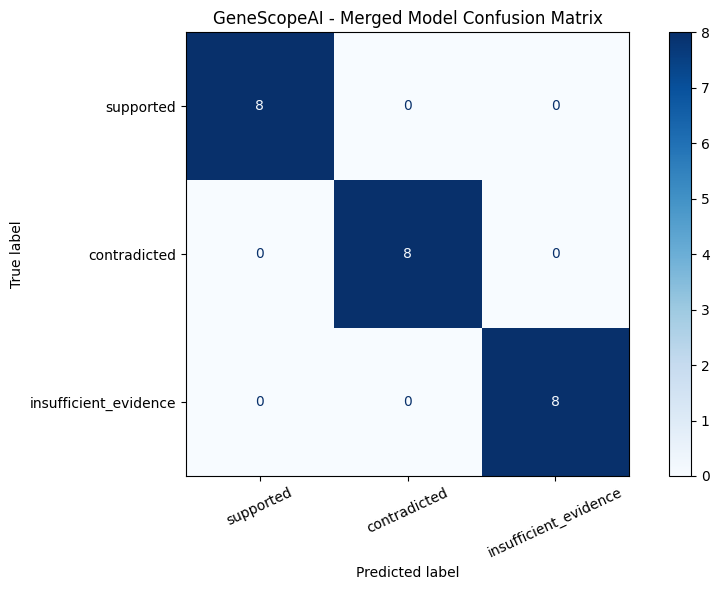

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    merged_results_df["actual"],
    merged_results_df["predicted"],
    labels=LABELS
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
)

fig, ax = plt.subplots(figsize=(9, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=25
)

ax.set_title(
    "GeneScopeAI - Merged Model Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    "GeneScopeAI_merged_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

files.download(
    "GeneScopeAI_merged_confusion_matrix.png"
)
